# T9: Feature literature and empirical search for alias / spurious-candidate separation

Companion notebook to `README.md` in this folder. Running top-to-bottom regenerates every figure in `figures/` from the saved results in `data/` (or the referenced `runs/` directory).

In [1]:
# Setup: make the flat claude_files package importable and load shared helpers.
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-10-14_t9-feature-search"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)


## Data
`data/` was produced by three scripts in this folder (run from the repo root):
1. `build_feature_table.py` -- fit `synthetic:n=200,seed=0` with the scorecard's default pipeline methods and extract the existing features (pass 1, `runs/t9_feature_table/`);
2. `new_features.py` -- add the new alias features at each candidate's fitted period (pass 2, no refitting);
3. `analysis.py` -- AUCs, redundancy, decline and arbitration tables into `data/`.

Outcome labels come from `evaluation.classify_period(fitted_P, P_eq, REL_TOL, period_range)`; *success* = correct + diffrot.

In [2]:
cand = pd.read_csv(DATA / "candidates.csv.gz")
cand = cand[cand["outcome"].notna()].copy()
stars = pd.read_csv(DATA / "stars.csv")
auc = pd.read_csv(DATA / "auc_overall.csv")
auc_bin = pd.read_csv(DATA / "auc_by_bin.csv")
ws = pd.read_csv(DATA / "auc_within_star.csv")
NEW = ["acf_height_at_P", "acf_half_lag_contrast", "acf_odd_even_contrast", "fold_half_corr", "fold_half_corr_at_2P"]
SUCC = ("correct", "diffrot")
cand["group"] = np.where(cand["outcome"].isin(SUCC), "success", cand["outcome"])
BINS = list(ev.PERIOD_BIN_LABELS)
# validated categorical slots 1-4 (dataviz reference palette, light mode)
COL = {"success": "#2a78d6", "half": "#eb6834", "double": "#1baf7a", "wrong": "#eda100"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 9})
print(cand["group"].value_counts().to_string()); print(len(stars), "stars")

group
wrong      2721
success     536
half        239
double      222
200 stars


## 1. Univariate separation: pooled AUC
AUC = P(success candidate has the higher value). 0.5 = useless; far from 0.5 in either direction = useful (direction matters only for interpretation).

In [3]:
p = auc.pivot(index="feature", columns="contrast", values="auc")
p.columns = [c.replace("succ_vs_", "") for c in p.columns]
w = ws.pivot(index="feature", columns="contrast", values="concordance")
w.columns = ["within_star_" + c.replace("succ_vs_", "") for c in w.columns]
tab = p.join(w)
tab["sep_alias"] = (tab["alias"] - 0.5).abs()
tab["new"] = tab.index.isin(NEW)
pd.set_option("display.width", 200)
tab.sort_values("sep_alias", ascending=False).round(3).head(25)

,alias,double,half,wrong,within_star_alias,within_star_double,within_star_half,within_star_wrong,sep_alias,new
feature,,,,,,,,,,
acf_half_lag_contrast,0.831,0.829,0.833,0.808,0.809,0.804,0.814,0.837,0.331,True
fold_half_corr,0.170,0.057,0.275,0.201,0.142,0.076,0.205,0.212,0.330,True
mean_peak_trough_depth_snr,0.801,0.709,0.886,0.840,0.853,0.736,0.965,0.908,0.301,False
fold_half_corr_at_2P,0.782,0.609,0.943,0.846,0.758,0.615,0.895,0.857,0.282,True
acf_height_at_P,0.756,0.550,0.947,0.730,0.806,0.646,0.960,0.788,0.256,True
combined_method_strength,0.752,0.793,0.715,0.796,0.893,0.880,0.906,0.891,0.252,False
min_peak_trough_depth_snr,0.751,0.586,0.904,0.687,0.746,0.531,0.951,0.721,0.251,False
mean_height_snr,0.735,0.692,0.775,0.864,0.822,0.796,0.846,0.915,0.235,False
min_height_snr,0.734,0.626,0.835,0.735,0.769,0.625,0.907,0.746,0.234,False


## 2. AUC by true-period bin (top features)
Heatmap of pooled AUC per bin for the strongest features, split by contrast. Orange < 0.5 < blue; the cell text is the AUC. `>30d` has only 8 stars -- read it as anecdotal.

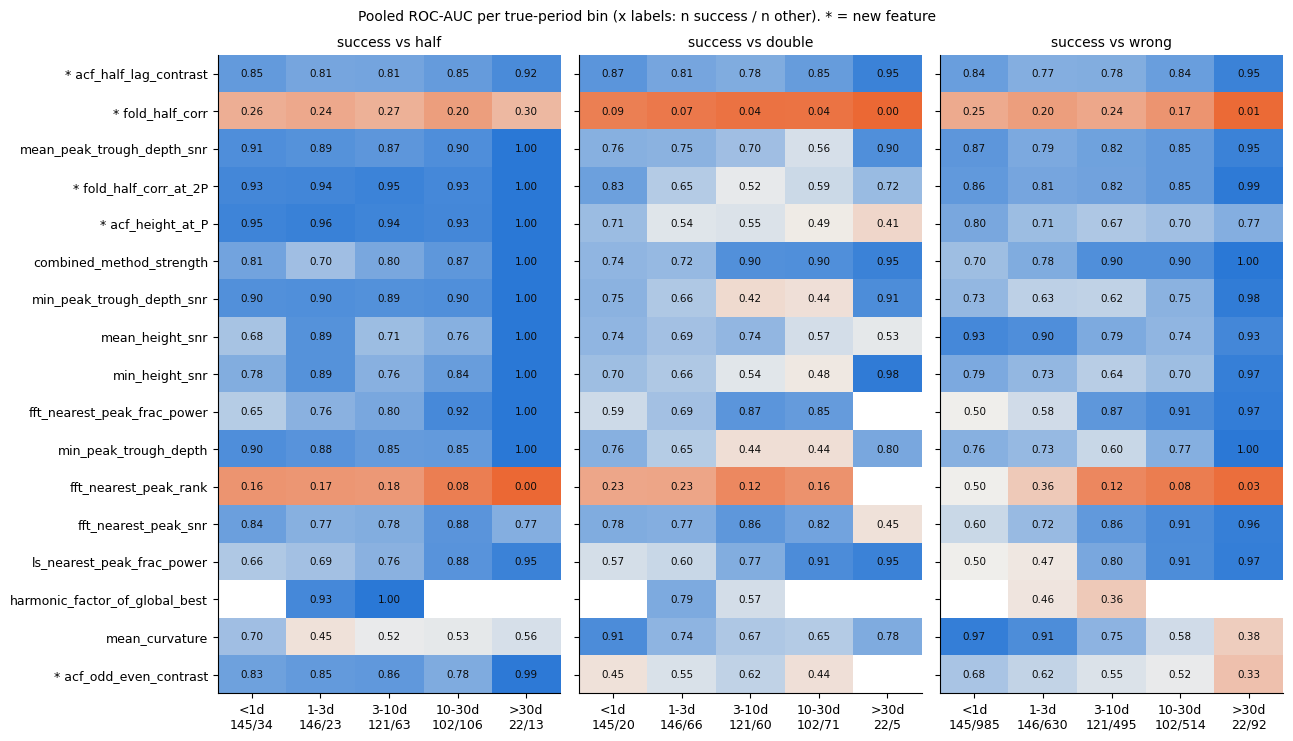

In [4]:
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])
top = (tab.sort_values("sep_alias", ascending=False).index[:16]).tolist()
for f in NEW:
    if f not in top: top.append(f)
fig, axes = plt.subplots(1, 3, figsize=(13, 7.5), sharey=True)
for ax, con in zip(axes, ["succ_vs_half", "succ_vs_double", "succ_vs_wrong"]):
    m = auc_bin[auc_bin.contrast == con].pivot(index="feature", columns="period_bin", values="auc").reindex(index=top, columns=BINS)
    ax.imshow(m.to_numpy(), cmap=div, vmin=0, vmax=1, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.iat[i, j]
            ax.text(j, i, "" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="#0b0b0b")
    n = auc_bin[(auc_bin.contrast == con) & (auc_bin.feature == "redchi")].set_index("period_bin").reindex(BINS)
    ax.set_xticks(range(len(BINS)), [f"{b}\n{int(a)}/{int(c)}" for b, a, c in zip(BINS, n.n_pos, n.n_neg)])
    ax.set_title(con.replace("succ_vs_", "success vs "), fontsize=10); ax.grid(False)
axes[0].set_yticks(range(len(top)), [("* " if f in NEW else "") + f for f in top])
fig.suptitle("Pooled ROC-AUC per true-period bin (x labels: n success / n other). * = new feature", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "fig_auc_by_bin.png", dpi=130); plt.show()

## 3. Distributions of the new features, split by outcome
Density histograms over all candidates. `fold_half_corr` piles up at ~1 for **double** candidates; `fold_half_corr_at_2P` and `acf_odd_even_contrast` push **half** candidates low; `acf_half_lag_contrast` is ~0 for both aliases and for most **wrong** candidates.

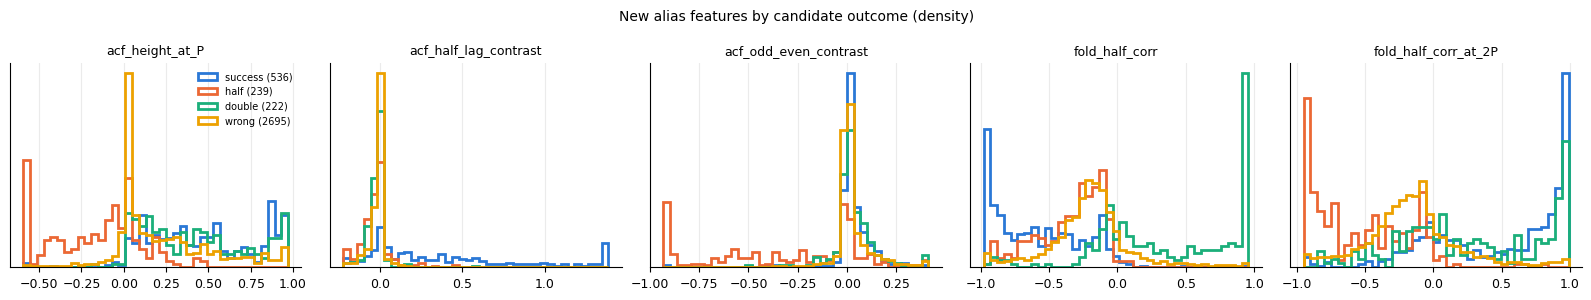

In [5]:
def dist_grid(feats, fname, title, clip=(1, 99)):
    fig, axes = plt.subplots(1, len(feats), figsize=(3.2 * len(feats), 3.0))
    for ax, f in zip(np.atleast_1d(axes), feats):
        x = cand[f].astype(float)
        lo, hi = np.nanpercentile(x, clip)
        bins = np.linspace(lo, hi, 40)
        for g in ["success", "half", "double", "wrong"]:
            v = x[cand["group"] == g].dropna()
            ax.hist(np.clip(v, lo, hi), bins=bins, density=True, histtype="step", lw=2, color=COL[g], label=f"{g} ({len(v)})")
        ax.set_title(f, fontsize=9); ax.set_yticks([])
    np.atleast_1d(axes)[0].legend(fontsize=7, frameon=False)
    fig.suptitle(title, fontsize=10); fig.tight_layout(); fig.savefig(FIG / fname, dpi=130); plt.show()

dist_grid(NEW, "fig_new_feature_dists.png", "New alias features by candidate outcome (density)")

## 4. Most and least useful existing features
Top row: the three existing features with the largest success-vs-alias separation. Bottom row: three with essentially none (star-level features are constant within a star, so they cannot rank candidates -- they only matter for decline prediction).

best: ['mean_peak_trough_depth_snr', 'combined_method_strength', 'min_peak_trough_depth_snr'] worst: ['flux_skewness', 'fliper_band_2', 'rvar_p2p_snr']


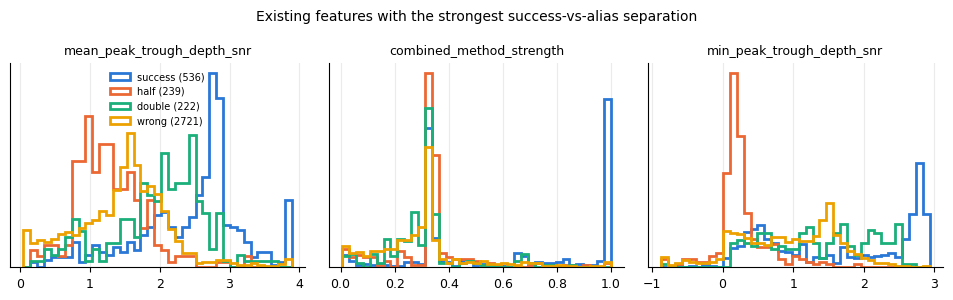

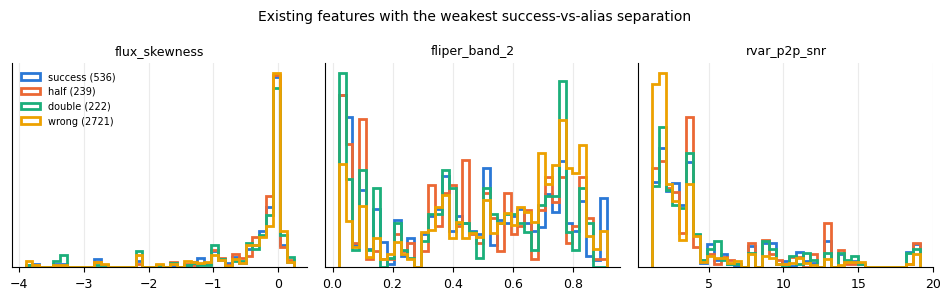

In [6]:
ex = tab[~tab["new"]].dropna(subset=["alias"]).sort_values("sep_alias", ascending=False)
best3 = ex.index[:3].tolist(); worst3 = ex.index[-3:].tolist()
print("best:", best3, "worst:", worst3)
dist_grid(best3, "fig_existing_best.png", "Existing features with the strongest success-vs-alias separation")
dist_grid(worst3, "fig_existing_worst.png", "Existing features with the weakest success-vs-alias separation")

## 5. Within-star concordance (what a pairwise ranker sees)
For every (success, alias) candidate pair **from the same star**, the fraction where the success candidate has the higher value. Period-like features are excluded from this plot: within a star they trivially order P/2 < P < 2P (concordance 0 or 1 for half and double separately) but cannot tell which of the three is right.

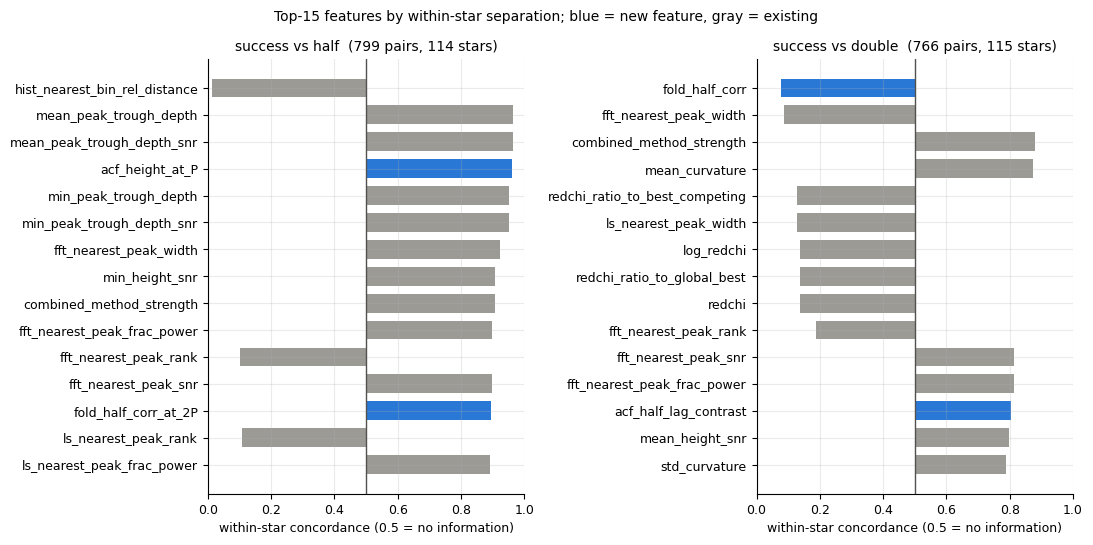

In [7]:
trivial = {"period", "log_period", "fitted_P", "period_frac_of_baseline", "n_cycles_spanned", "harmonic_factor_of_global_best", "s_ph"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, con in zip(axes, ["succ_vs_half", "succ_vs_double"]):
    d = ws[(ws.contrast == con) & ~ws.feature.isin(trivial)].dropna(subset=["concordance"]).sort_values("sep", ascending=False).head(15)[::-1]
    c = ["#2a78d6" if f in NEW else "#9b9a95" for f in d.feature]
    ax.barh(range(len(d)), d.concordance - 0.5, left=0.5, color=c, height=0.7)
    ax.set_yticks(range(len(d)), d.feature); ax.axvline(0.5, color="#52514e", lw=1)
    ax.set_xlim(0, 1); ax.set_xlabel("within-star concordance (0.5 = no information)")
    n = d.n_pairs.max(); s = d.n_stars.max()
    ax.set_title(f"{con.replace('succ_vs_', 'success vs ')}  ({n} pairs, {s} stars)", fontsize=10)
fig.suptitle("Top-15 features by within-star separation; blue = new feature, gray = existing", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "fig_within_star.png", dpi=130); plt.show()

## 6. Redundancy and near-constant features (flagged, not removed)

In [8]:
red = pd.read_csv(DATA / "redundant_pairs.csv"); nc = pd.read_csv(DATA / "near_constant.csv")
print(f"{len(red)} pairs with |Spearman rho| > 0.95"); display(red.round(3))
print(f"{len(nc)} near-constant features"); display(nc)
X = cand[NEW + [c for c in tab.index if c not in NEW]].astype(float)
rho = X.corr(method="spearman").loc[NEW].drop(columns=NEW).abs()
print("max |rho| between each new feature and any existing feature:")
print(pd.DataFrame({"max_abs_rho": rho.max(axis=1).round(2), "most_similar": rho.idxmax(axis=1)}))

23 pairs with |Spearman rho| > 0.95


,feature_a,feature_b,spearman
0,period,log_period,1.000
1,period,period_frac_of_baseline,1.000
2,log_period,period_frac_of_baseline,1.000
3,redchi,log_redchi,1.000
4,n_cycles_spanned,fitted_P,-1.000
5,flux_std,von_neumann_eta,-0.998
6,flux_std,star_g_acf,0.996
7,von_neumann_eta,star_g_acf,-0.994
8,log_period,n_cycles_spanned,-0.993
9,period,fitted_P,0.993


26 near-constant features


,feature,n_unique,top_value_frac,finite_frac
0,passes_redchi,2,0.998655,1.0
1,passes_height_snr,2,0.993545,1.0
2,baseline_days,1,1.000000,1.0
3,n_acf_points,1,1.000000,1.0
4,ls_short_nearest_peak_rank,0,1.000000,0.0
5,ls_short_nearest_peak_frac_power,0,1.000000,0.0
6,ls_short_nearest_peak_rel_distance,0,1.000000,0.0
7,ls_short_nearest_peak_width,0,1.000000,0.0
8,ls_short_nearest_peak_fap,0,1.000000,0.0
9,fft_short_nearest_peak_rank,0,1.000000,0.0


max |rho| between each new feature and any existing feature:
                       max_abs_rho                    most_similar
acf_height_at_P               0.56                         acf_std
acf_half_lag_contrast         0.48       min_peak_trough_depth_snr
acf_odd_even_contrast         0.33  harmonic_factor_of_global_best
fold_half_corr                0.33          mean_peak_trough_depth
fold_half_corr_at_2P          0.42       min_peak_trough_depth_snr


## 7. Arbitration (open issue 12)
Where does the hand-tuned arbitration lose stars that had a successful candidate?

In [9]:
lb = pd.read_csv(DATA / "loss_breakdown.csv"); display(lb)
rules = pd.read_csv(DATA / "arbitration_rules.csv"); gbm = pd.read_csv(DATA / "arbitration_gbm.csv")
display(rules.round(3)); display(gbm.round(3))

,final_outcome,False,True
0,correct,0,92
1,diffrot,0,42
2,half,4,1
3,none,22,0
4,wrong,4,5


,rule,overall,n,<1d,1-3d,3-10d,10-30d,>30d
0,current: min redchi among passed (no decline),0.680,200,0.647,0.711,0.833,0.698,0.000
1,min redchi (all),0.390,200,0.397,0.578,0.528,0.140,0.000
2,"max n_agreeing_methods, then min redchi",0.365,200,0.338,0.289,0.417,0.442,0.375
3,max combined_method_strength,0.680,200,0.456,0.644,0.889,0.837,1.000
4,max mean_peak_trough_depth_snr (passed),0.740,200,0.662,0.756,0.861,0.791,0.500
5,max mean_height_snr (passed),0.695,200,0.632,0.711,0.833,0.721,0.375
6,max coverage_at_fit (passed),0.625,200,0.544,0.600,0.750,0.721,0.375
7,max acf_half_lag_contrast (passed),0.750,200,0.662,0.756,0.861,0.791,0.750
8,"max acf_half_lag_contrast (all, ignore gates)",0.760,200,0.647,0.711,0.889,0.837,1.000
9,"max mean_peak_trough_depth_snr (all, ignore ga...",0.610,200,0.559,0.622,0.778,0.512,0.750


,feature_set,n_features,overall,n,<1d,1-3d,3-10d,10-30d,>30d
0,existing,97,0.765,200,0.662,0.733,0.861,0.837,1.0
1,existing+new,102,0.775,200,0.676,0.733,0.889,0.837,1.0


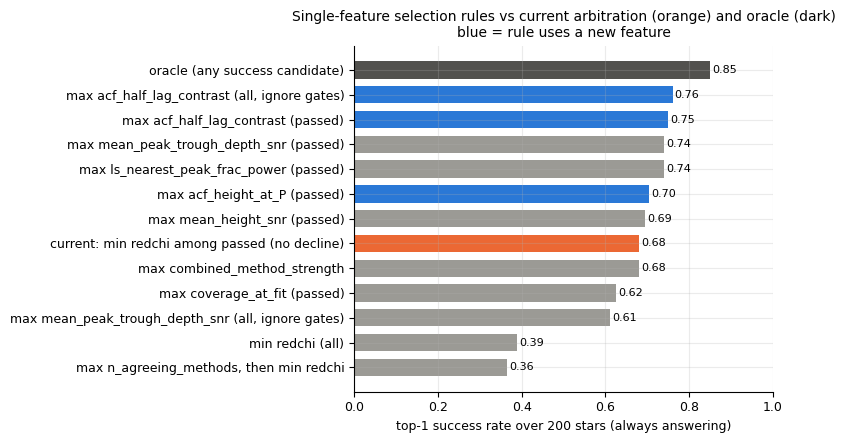

In [10]:
r = rules.copy()
fig, ax = plt.subplots(figsize=(8, 4.5))
order = r.sort_values("overall")
c = ["#52514e" if "oracle" in x else ("#eb6834" if x.startswith("current") else ("#2a78d6" if any(f in x for f in NEW) else "#9b9a95")) for x in order.rule]
ax.barh(range(len(order)), order.overall, color=c, height=0.7)
for i, v in enumerate(order.overall): ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_yticks(range(len(order)), order.rule); ax.set_xlim(0, 1)
ax.set_xlabel("top-1 success rate over 200 stars (always answering)")
ax.set_title("Single-feature selection rules vs current arbitration (orange) and oracle (dark)\nblue = rule uses a new feature", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "fig_arbitration_rules.png", dpi=130); plt.show()

## 8. Decline prediction
Rule: pick the candidate with the largest `acf_half_lag_contrast` over **all** candidates (no gates), answer only if that value >= threshold. Curve = threshold sweep; the orange point is the current pipeline. Threshold chosen in-sample on these 200 stars -- treat the exact value as illustrative.

recoverable
                 feature   auc  n_pos  n_neg
         acf_height_at_P 0.942    170     30
         coverage_at_fit 0.923    139      6
             t0_err_frac 0.087    170     30
                 acf_std 0.910    170     30
   acf_half_lag_contrast 0.898    170     30
    fold_half_corr_at_2P 0.898    170     30
combined_method_strength 0.882    170     30
    ls_nearest_peak_rank 0.119    170     30
answer_ok
                    feature   auc  n_pos  n_neg
      min_peak_trough_depth 0.992    134     18
     mean_peak_trough_depth 0.989    134     18
      acf_half_lag_contrast 0.981    134     18
      fft_nearest_peak_rank 0.020    134     18
fft_nearest_peak_frac_power 0.979    134     18
  min_peak_trough_depth_snr 0.978    134     18
                t0_err_frac 0.023    134     18
       fft_nearest_peak_snr 0.976    134     18


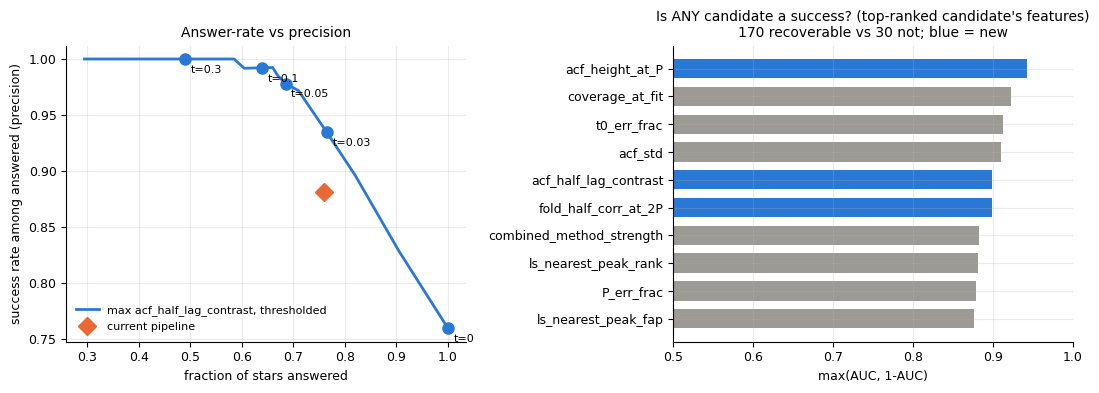

In [11]:
dc = pd.read_csv(DATA / "decline_curve.csv"); cur = pd.read_csv(DATA / "decline_current.csv").iloc[0]
dstar = pd.read_csv(DATA / "decline_auc.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(dc.answered, dc.precision, color="#2a78d6", lw=2, label="max acf_half_lag_contrast, thresholded")
for t in (0.0, 0.03, 0.05, 0.1, 0.3):
    rr = dc.iloc[(dc.threshold - t).abs().argmin()]
    ax.plot(rr.answered, rr.precision, "o", color="#2a78d6", ms=8); ax.annotate(f"t={t:g}", (rr.answered, rr.precision), xytext=(4, -10), textcoords="offset points", fontsize=8)
ax.plot(cur.answered, cur.precision, "D", color="#eb6834", ms=9, label="current pipeline")
ax.set_xlabel("fraction of stars answered"); ax.set_ylabel("success rate among answered (precision)")
ax.legend(frameon=False, fontsize=8); ax.set_title("Answer-rate vs precision", fontsize=10)
ax = axes[1]
for q, col in (("recoverable", "#2a78d6"), ("answer_ok", "#1baf7a")):
    d = dstar[dstar.question == q].dropna(subset=["auc"]).sort_values("sep", ascending=False).head(8)
    print(q); print(d[["feature", "auc", "n_pos", "n_neg"]].round(3).to_string(index=False))
d = dstar[dstar.question == "recoverable"].dropna(subset=["auc"]).sort_values("sep", ascending=False).head(10)[::-1]
ax.barh(range(len(d)), d.sep + 0.5, color=["#2a78d6" if f in NEW else "#9b9a95" for f in d.feature], height=0.7)
ax.set_yticks(range(len(d)), d.feature); ax.set_xlim(0.5, 1); ax.set_xlabel("max(AUC, 1-AUC)")
ax.set_title("Is ANY candidate a success? (top-ranked candidate's features)\n170 recoverable vs 30 not; blue = new", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "fig_decline.png", dpi=130); plt.show()

## 9. Failure modes: what the current arbitration picks vs the success candidate
Four representative lost stars. Left: ACF with the selected (orange) and best success (blue) candidate's multiples marked. Right: the light curve folded at each period (one 4-cycle segment's worth of binned profiles, all segments overlaid in light gray, mean in color). Titles give the new-feature values.

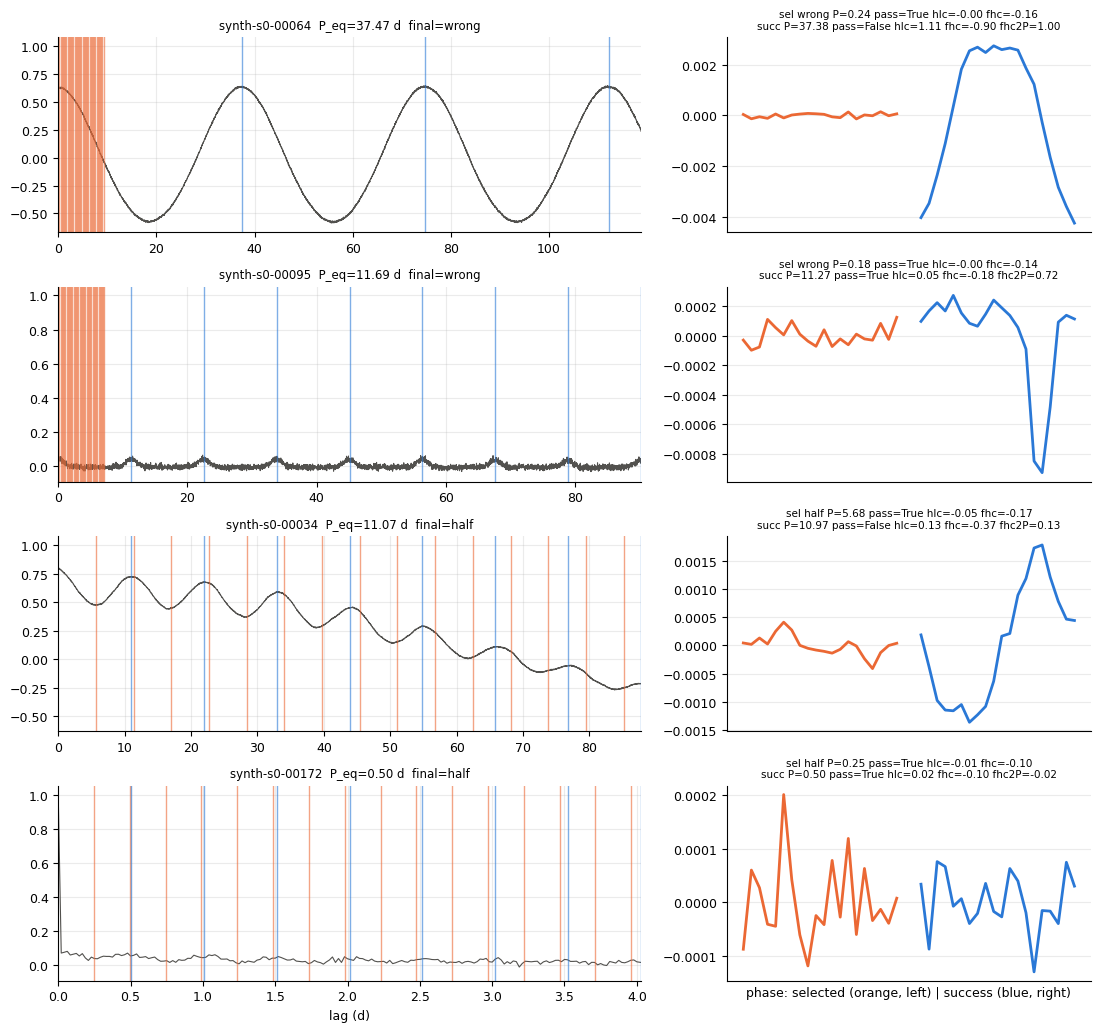

36 stars with a success candidate but no final success


In [12]:
from synthetic import make_suite
from acf_utils import compute_acf
suite = {lc.star_id: lc for lc in make_suite(200, seed=0)}
def show(sid, ax_acf, ax_f):
    d = cand[cand.star_id == sid]; lc = suite[sid]; lags, acf = compute_acf(lc.time, lc.flux)
    sel = d[d.selected].iloc[0] if d.selected.any() else d.iloc[0]
    su = d[d.outcome.isin(SUCC)].sort_values("redchi").iloc[0]
    ax_acf.plot(lags, acf, color="#52514e", lw=0.8)
    for row, col in ((sel, "#eb6834"), (su, "#2a78d6")):
        for k in range(1, 40):
            if k * row.fitted_P > lags[-1]: break
            ax_acf.axvline(k * row.fitted_P, color=col, lw=1, alpha=0.6)
    ax_acf.set_xlim(0, min(lags[-1], 8 * max(sel.fitted_P, su.fitted_P)))
    ax_acf.set_title(f"{sid}  P_eq={lc.true_period:.2f} d  final={d.final_outcome.iloc[0]}", fontsize=8.5)
    ok = np.isfinite(lc.flux)
    for row, col, off in ((sel, "#eb6834", 0), (su, "#2a78d6", 1)):
        ph = (lc.time[ok] / row.fitted_P) % 1
        b = np.minimum((ph * 20).astype(int), 19)
        prof = np.bincount(b, lc.flux[ok], 20) / np.maximum(np.bincount(b, minlength=20), 1)
        ax_f.plot(np.arange(20) / 20 + off * 1.1, prof - np.mean(prof), color=col, lw=2)
        ax_f.text(off * 1.1, ax_f.get_ylim()[1] if off else 0, "", fontsize=7)
    ax_f.set_xticks([]); ax_f.set_title(
        f"sel {sel.outcome} P={sel.fitted_P:.2f} pass={sel.passed_gates} hlc={sel.acf_half_lag_contrast:.2f} fhc={sel.fold_half_corr:.2f}\n"
        f"succ P={su.fitted_P:.2f} pass={su.passed_gates} hlc={su.acf_half_lag_contrast:.2f} fhc={su.fold_half_corr:.2f} fhc2P={su.fold_half_corr_at_2P:.2f}", fontsize=7.5)
lost = stars[stars.any_success_cand & ~stars.final_success]
ex_ids = ["synth-s0-00064", "synth-s0-00095", "synth-s0-00034", "synth-s0-00172"]
fig, axes = plt.subplots(len(ex_ids), 2, figsize=(11, 2.6 * len(ex_ids)), gridspec_kw=dict(width_ratios=[1.6, 1]))
for i, sid in enumerate(ex_ids): show(sid, axes[i, 0], axes[i, 1])
axes[-1, 0].set_xlabel("lag (d)"); axes[-1, 1].set_xlabel("phase: selected (orange, left) | success (blue, right)")
fig.tight_layout(); fig.savefig(FIG / "fig_failure_examples.png", dpi=120); plt.show()
print(len(lost), "stars with a success candidate but no final success")

## 10. Cost of the new features
Measured in `new_features.py` on this run (13-sector, 30-min light curves): see the printout in `runs/` or the README. The per-candidate cost is dominated by the two vectorized phase folds.